# Análisis Exploratorio de Datos y Preprocesamiento

**Conjunto de Datos:** CIC-IDS2017 (Canadian Institute for Cybersecurity)  
**Enfoque:** Análisis comparativo de modelos de aprendizaje automático para la detección de intrusiones.

## Fundamentación
El conjunto de datos CIC-IDS2017 constituye un estándar contemporáneo para la evaluación de Sistemas de Detección de Intrusos (IDS) basados en algoritmos de aprendizaje automático. El presente documento detalla la primera fase metodológica del estudio experimental. 

### Objetivos del Análisis:
1. **Consolidación a Gran Escala:** Extracción y concatenación de la totalidad de las instancias presentes en los archivos de captura originales.
2. **Inspección Estructural:** Evaluación de las dimensiones de la matriz de características, tipos de datos y huella de memoria.
3. **Depuración de Anomalías Matemáticas:** Identificación y tratamiento de valores nulos (`NaN`) e indeterminaciones (`Infinity`) resultantes de la división por cero durante el cálculo de flujos de red.
4. **Reducción de Dimensionalidad:** Detección y eliminación de variables de varianza nula (características constantes).
5. **Análisis de Distribución de Clases:** Cuantificación del desbalanceo estadístico entre el tráfico benigno y los vectores de ataque.

---
### Requisitos del Entorno:
*   **Dependencias:** `pandas`, `numpy`, `matplotlib`, `seaborn`.
*   **Almacenamiento:** Los archivos fuente (formato `.csv`) deben encontrarse en el directorio relativo `../data/raw/`.

In [ ]:
# ==============================================================================
# Importación de Bibliotecas y Configuración del Entorno
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from pathlib import Path

# Supresión de advertencias no críticas para mantener la legibilidad de la salida
warnings.filterwarnings('ignore')

# Configuración de parámetros de visualización para representaciones gráficas
pd.set_option('display.max_columns', None)
sns.set_theme(style="whitegrid", context="paper")

# Establecimiento de la semilla de inicialización para garantizar la reproducibilidad
SEED = 42
np.random.seed(SEED)

In [ ]:
# ==============================================================================
# Unificación de los archivos CSV en un único DataFrame
# ==============================================================================
RAW_DATA_DIR = Path("../data/raw")
archivos_csv = list(RAW_DATA_DIR.glob("*.csv"))

dataframes = []

print("[INFO] Iniciando el proceso de consolidación de datos...")
if not archivos_csv:
    print("[ERROR] Directorio vacío o inexistente. Verifique la ruta '../data/raw/'.")
else:
    for file_path in archivos_csv:
        print(f"[INFO] Extrayendo datos de: {file_path.name}")
        # Se asigna low_memory=False para prevenir advertencias de tipos de datos mixtos en lecturas masivas
        df_temp = pd.read_csv(file_path, low_memory=False)
        
        # Normalización sintáctica de las cabeceras
        df_temp.columns = df_temp.columns.str.strip()
        dataframes.append(df_temp)

    # Generación del DataFrame global
    df = pd.concat(dataframes, ignore_index=True)
    print(f"\n[RESULTADO] Matriz de características consolidada.")
    print(f"[RESULTADO] Dimensiones del dataset (Instancias, Atributos): {df.shape}")

[INFO] Iniciando el proceso de consolidación de datos...
[INFO] Extrayendo datos de: Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv
[INFO] Extrayendo datos de: Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv
[INFO] Extrayendo datos de: Friday-WorkingHours-Morning.pcap_ISCX.csv
[INFO] Extrayendo datos de: Monday-WorkingHours.pcap_ISCX.csv
[INFO] Extrayendo datos de: Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv
[INFO] Extrayendo datos de: Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv
[INFO] Extrayendo datos de: Tuesday-WorkingHours.pcap_ISCX.csv
[INFO] Extrayendo datos de: Wednesday-workingHours.pcap_ISCX.csv

[RESULTADO] Matriz de características consolidada.
[RESULTADO] Dimensiones del dataset (Instancias, Atributos): (2830743, 79)


In [ ]:
# ==============================================================================
# Auditoría de tipos de datos y cálculo de memoria
# ==============================================================================
if 'df' in locals():
    print("[INFO] Resumen de Tipos de Datos (Dtypes):\n")
    print(df.dtypes.value_counts())
    
    # Cálculo de la huella de memoria en Gigabytes
    memoria_gb = df.memory_usage(deep=True).sum() / (1024 ** 3)
    print(f"\n[INFO] Consumo de memoria estimado: {memoria_gb:.2f} GB")
else:
    print("[ERROR] La matriz 'df' no ha sido inicializada.")

[INFO] Resumen de Tipos de Datos (Dtypes):

int64      54
float64    24
str         1
Name: count, dtype: int64

[INFO] Consumo de memoria estimado: 1.79 GB


In [ ]:
# ==============================================================================
# Normalización de valores atípicos y eliminación de filas inválidas
# ==============================================================================
if 'df' in locals():
    print("[INFO] Iniciando barrido de anomalías...")
    
    # Sustitución algorítmica de infinitos por valores nulos estándar
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    
    # Cuantificación de vectores afectados
    filas_afectadas = df.isna().any(axis=1).sum()
    porcentaje_afectacion = (filas_afectadas / len(df)) * 100
    
    print(f"[INFO] Instancias con valores NaN/Inf: {filas_afectadas} ({porcentaje_afectacion:.4f}% del total)")
    
    if filas_afectadas > 0:
        df.dropna(inplace=True)
        print(f"[RESULTADO] Anomalías eliminadas. Dimensiones actualizadas: {df.shape}")
else:
    print("[ERROR] La matriz 'df' no ha sido inicializada.")

[INFO] Iniciando barrido de anomalías...
[INFO] Instancias con valores NaN/Inf: 2867 (0.1013% del total)
[RESULTADO] Anomalías eliminadas. Dimensiones actualizadas: (2827876, 79)


In [ ]:
# ==============================================================================
# Detección y filtrado de características constantes
# ==============================================================================
if 'df' in locals():
    print("[INFO] Analizando varianza de características...")
    
    # Identificación de variables con cardinalidad igual a 1
    columnas_constantes = [col for col in df.columns if df[col].nunique() == 1]
    
    print(f"[INFO] Características de varianza nula detectadas: {len(columnas_constantes)}")
    if columnas_constantes:
        print(f"[INFO] Variables a eliminar: {', '.join(columnas_constantes)}")
        df.drop(columns=columnas_constantes, inplace=True)
        print(f"[RESULTADO] Dimensionalidad reducida. Dimensiones actualizadas: {df.shape}")
else:
    print("[ERROR] La matriz 'df' no ha sido inicializada.")

[INFO] Analizando varianza de características...
[INFO] Características de varianza nula detectadas: 8
[INFO] Variables a eliminar: Bwd PSH Flags, Bwd URG Flags, Fwd Avg Bytes/Bulk, Fwd Avg Packets/Bulk, Fwd Avg Bulk Rate, Bwd Avg Bytes/Bulk, Bwd Avg Packets/Bulk, Bwd Avg Bulk Rate
[RESULTADO] Dimensionalidad reducida. Dimensiones actualizadas: (2827876, 71)


[INFO] Distribución de Clases (Frecuencia Absoluta):

Label
BENIGN                        2271320
DoS Hulk                       230124
PortScan                       158804
DDoS                           128025
DoS GoldenEye                   10293
FTP-Patator                      7935
SSH-Patator                      5897
DoS slowloris                    5796
DoS Slowhttptest                 5499
Bot                              1956
Web Attack � Brute Force         1507
Web Attack � XSS                  652
Infiltration                       36
Web Attack � Sql Injection         21
Heartbleed                         11
Name: count, dtype: int64


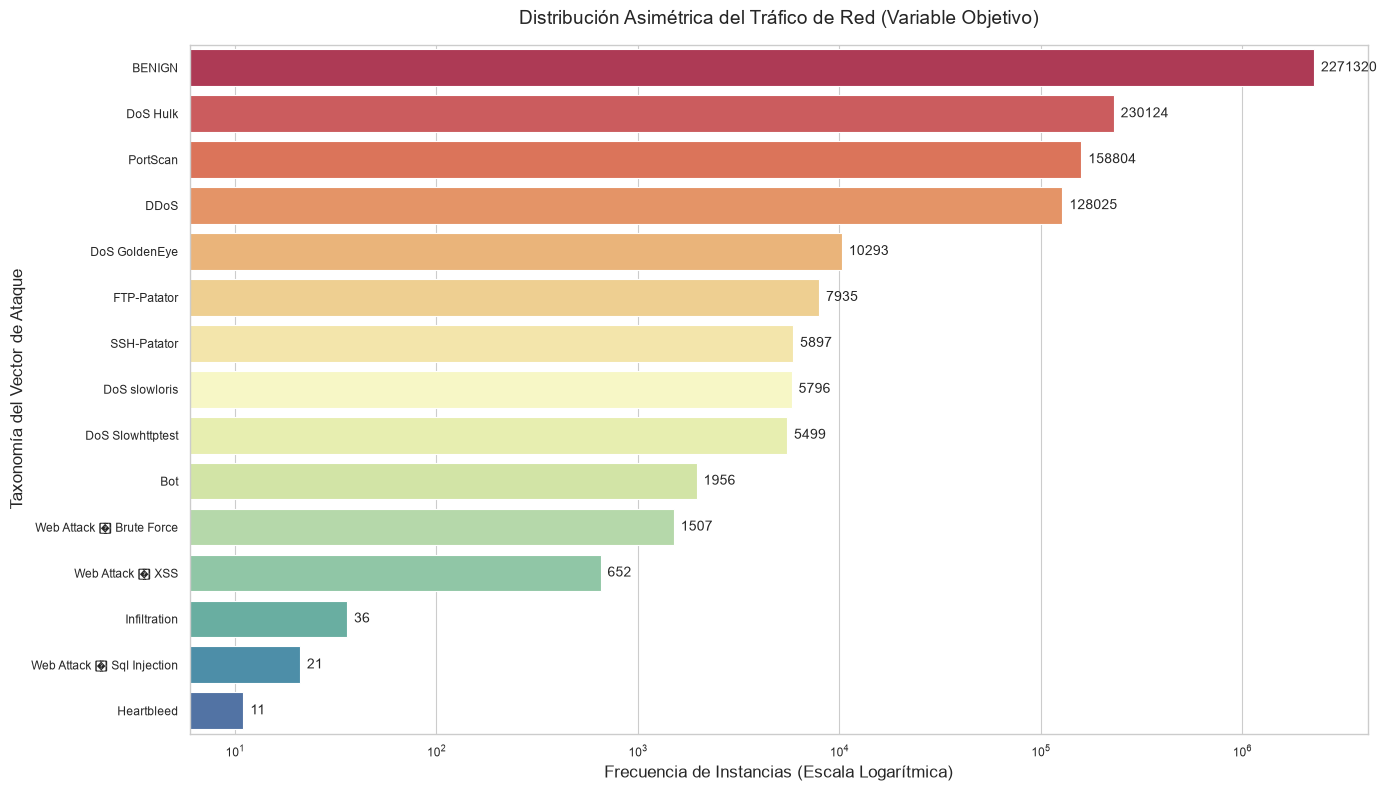

In [ ]:
# ==============================================================================
# Visualización de la distribución de clases de la variable objetivo
# ==============================================================================
if 'df' in locals() and 'Label' in df.columns:
    conteo_clases = df['Label'].value_counts()
    print("[INFO] Distribución de Clases (Frecuencia Absoluta):\n")
    print(conteo_clases)
    
    # Generación de representación gráfica con escala logarítmica (debido a asimetría severa)
    plt.figure(figsize=(14, 8))
    ax = sns.barplot(x=conteo_clases.values, y=conteo_clases.index, palette="Spectral")
    plt.title('Distribución Asimétrica del Tráfico de Red (Variable Objetivo)', fontsize=14, pad=15)
    plt.xlabel('Frecuencia de Instancias (Escala Logarítmica)', fontsize=12)
    plt.ylabel('Taxonomía del Vector de Ataque', fontsize=12)
    plt.xscale('log')  # Escala logarítmica para visibilizar clases minoritarias extremas
    
    # Anotación matemática de las barras
    for p in ax.patches:
        ax.annotate(f'{int(p.get_width())}', 
                    (p.get_width(), p.get_y() + p.get_height() / 2.), 
                    ha='left', va='center', 
                    xytext=(5, 0), textcoords='offset points', fontsize=10)
    
    plt.tight_layout()
    plt.show()
else:
    print("[ERROR] La columna objetivo 'Label' no se encuentra en el subespacio vectorial.")

In [ ]:
# ==============================================================================
# Guardado del DataFrame global depurado en formato CSV
# ==============================================================================
if 'df' in locals():
    print("[INFO] Iniciando proceso de serialización a formato CSV...")
    PROCESSED_DIR = Path("../data/processed")
    PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
    
    # Exportación del archivo global estructurado
    ruta_salida = PROCESSED_DIR / "cic_ids2017_global_depurado.csv"
    df.to_csv(ruta_salida, index=False)
    print(f"[RESULTADO] Matriz global exportada con éxito en la ruta: {ruta_salida}")
else:
    print("[ERROR] Operación interrumpida. No existen datos en memoria para exportar.")

[INFO] Iniciando proceso de serialización a formato CSV...
[RESULTADO] Matriz global exportada con éxito en la ruta: ..\data\processed\cic_ids2017_global_depurado.csv
